In [173]:
import os
import json
from typing import List, TypedDict

from langgraph.graph import StateGraph, END
from langchain_core.documents import Document
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_groq import ChatGroq

from langchain_community.vectorstores import FAISS
from langchain_community.retrievers import BM25Retriever
from langchain_classic.retrievers import EnsembleRetriever

In [174]:
from dotenv import load_dotenv

load_dotenv()

if not os.getenv("GROQ_API_KEY"):
    raise ValueError("GROQ_API_KEY is missing from .env")

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0
)

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2"
)

print("LLM and embedding model initialized.")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 1461.45it/s]


LLM and embedding model initialized.


In [175]:
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.5.6', 'langchain': '1.3.15'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000015DDF825A70>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000015DDF826D70>, model_name='openai/gpt-oss-20b', temperature=1e-08, model_kwargs={}, groq_api_key=SecretStr('**********'))

In [176]:
JSON_PATH = "flipkart_mobiles_chunks.json"

if not os.path.exists(JSON_PATH):
    raise FileNotFoundError(
        f"JSON file not found: {JSON_PATH}"
    )

with open(JSON_PATH, "r", encoding="utf-8") as f:
    data = json.load(f)

# Support either a list of documents or a wrapped JSON object.
if isinstance(data, dict):
    data = data.get("documents", data.get("chunks", []))

if not isinstance(data, list) or not data:
    raise ValueError("JSON must contain a non-empty list of documents.")

documents = []

for i, item in enumerate(data):
    if not isinstance(item, dict):
        continue

    content = item.get("page_content") or item.get("text")
    if not content:
        continue

    metadata = item.get("metadata", {})
    if not isinstance(metadata, dict):
        metadata = {}

    documents.append(
        Document(
            page_content=str(content),
            metadata=metadata
        )
    )

if not documents:
    raise ValueError(
        "No usable documents found. Check the JSON structure."
    )

print(f"Loaded {len(documents)} documents.")
print("\nExample document:")
print(documents[0].page_content)
print("\nMetadata:")
print(documents[0].metadata)

Loaded 430 documents.

Example document:
Brand: Apple. Model: iPhone SE. Color: Black. Processor: Water. Screen size category: Very Small. ROM: 64 GB. RAM: 2 GB. Display size: 4.7 inches. Rear cameras: 1. Front cameras: 1. Battery: 1800 mAh. Rating: 4.5. Number of ratings: 38645. Sales price: ₹32999. Discount percent: 0.17. Sales: 127.52.

Metadata:
{'row_id': 0, 'source': 'Flipkart Mobile - 2.pdf', 'brand': 'Apple', 'model': 'iPhone SE', 'RAM': 2, 'ROM': 64, 'battery_capacity': 1800, 'sales_price': 32999.0}


In [177]:
# A. Semantic vector store using FAISS
vector_store = FAISS.from_documents(
    documents=documents,
    embedding=embeddings
)


bm25_retriever.k = 30

faiss_retriever = vector_store.as_retriever(
    search_kwargs={"k": 30}
)

hybrid_retriever = EnsembleRetriever(
    retrievers=[bm25_retriever, faiss_retriever],
    weights=[0.5, 0.5]
)



print("FAISS vector store created.")
print("BM25 keyword retriever created.")
print("Hybrid retriever is ready.")

FAISS vector store created.
BM25 keyword retriever created.
Hybrid retriever is ready.


In [178]:
class AgentState(TypedDict):
    question: str
    context: List[Document]
    answer: str
    needs_retrieval: bool
    

In [179]:
def retrieve_documents(state: AgentState) -> AgentState:
    question = state["question"]

    # BM25 retrieves the top 25 relevant documents
    docs = hybrid_retriever.invoke(question)[:25]

    return {**state, "context": docs}


In [180]:
# test_query = "Which Poco phones have 8 GB RAM?"

# results = retriever.invoke(test_query)

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)
#     print("Metadata:", doc.metadata)

In [181]:
# import re

# def get_field(doc, field):
#     # First try the document text
#     pattern = rf"{field}\s*:\s*([^,\n.]+)"
#     match = re.search(pattern, doc.page_content, re.IGNORECASE)

#     if match:
#         return match.group(1).strip()

#     # Fall back to metadata
#     for key, value in doc.metadata.items():
#         if key.lower() == field.lower() and value is not None:
#             return str(value).strip()

#     return ""


# def exact_mobile_search(query):
#     q = query.lower()

#     # Detect the requested brand
#     brands = ["poco", "realme", "samsung", "apple",
#               "redmi", "xiaomi", "vivo", "oppo"]

#     required_brand = next((b for b in brands if b in q), None)

#     # Detect RAM requirement, e.g. "8 GB RAM"
#     ram_match = re.search(r"(\d+)\s*gb\s*ram", q)
#     required_ram = int(ram_match.group(1)) if ram_match else None

#     results = []

#     # Search ALL documents, not just the top retrieved candidates
#     for doc in documents:
#         brand = get_field(doc, "Brand").lower()
#         ram_text = get_field(doc, "RAM")

#         # Accept only an exact brand match
#         if required_brand and brand != required_brand:
#             continue

#         # Match RAM value
#         if required_ram is not None:
#             ram_match_doc = re.search(r"\d+", ram_text)
#             if not ram_match_doc:
#                 continue

#             if int(ram_match_doc.group()) != required_ram:
#                 continue

#         results.append(doc)

#     return results


# results = exact_mobile_search("Which Poco phones have 8 GB RAM?")

# print(f"Matching documents found: {len(results)}")

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)
#     print("Metadata:", doc.metadata)

In [182]:
# def smart_mobile_search(query: str, k: int = 5):
#     q = query.lower()

#     # Detect structured constraints
#     brands = [
#         "poco", "realme", "samsung", "apple",
#         "redmi", "xiaomi", "vivo", "oppo"
#     ]
#     required_brand = next(
#         (brand for brand in brands if brand in q), None
#     )

#     ram_match = re.search(r"(\d+)\s*gb\s*ram", q)
#     required_ram = int(ram_match.group(1)) if ram_match else None

#     # Use exact filtering when brand or RAM is specified
#     if required_brand or required_ram is not None:
#         matches = exact_mobile_search(query)

#         if matches:
#             return matches[:k]

#     # Otherwise, use the hybrid retriever
#     return retriever.invoke(query)[:k]


In [183]:
from sentence_transformers import CrossEncoder

# Load a reranking model
reranker = CrossEncoder(
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

print("Reranker loaded successfully!")

Loading weights: 100%|██████████| 105/105 [00:00<00:00, 2167.62it/s]


Reranker loaded successfully!


In [184]:
def rerank_documents(question, documents, top_k=10):
    if not documents:
        return []

    pairs = [
        (question, doc.page_content)
        for doc in documents
    ]

    scores = reranker.predict(pairs)

    ranked_docs = sorted(
        zip(documents, scores),
        key=lambda item: item[1],
        reverse=True
    )

    return [
        doc for doc, score in ranked_docs[:top_k]
    ]

In [185]:
# results = bm25_retriever.invoke(
#     "Which Poco phones have 8 GB RAM?"
# )[:25]

# print(f"Matching documents retrieved: {len(results)}")

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)

# bm25_retriever.k = 25

# query = "Poco phones with 8 GB RAM"

# results = bm25_retriever.invoke(query)

# print("Documents retrieved:", len(results))

# for i, doc in enumerate(results, start=1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)


# query = "Which Poco phones have 8 GB RAM?"
# results = hybrid_retriever.invoke(query)

# print("Retrieved documents:", len(results))

# for i, doc in enumerate(results, 1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)


def filter_by_battery_capacity(documents, target_capacity):
    return [
        doc for doc in documents
        if doc.metadata.get("battery_capacity") == target_capacity
    ]
query = "Which phones have a 6000 mAh battery?"

candidates = hybrid_retriever.invoke(query)

ranked_results = rerank_documents(
    query,
    candidates,
    top_k=30
)

matching_results = filter_by_battery_capacity(
    ranked_results,
    6000
)

# print("Exact battery matches:", len(matching_results))

# for i, doc in enumerate(matching_results, 1):
#     print(
#         f"{i}. {doc.metadata.get('brand')} "
#         f"{doc.metadata.get('model')} | "
#         f"Battery: {doc.metadata.get('battery_capacity')} mAh"
#     )

In [186]:
def remove_duplicate_models(docs):
    unique_docs = {}

    for doc in docs:
        brand = get_field(doc, "Brand").strip()
        model = get_field(doc, "Model").strip()
        ram = get_field(doc, "RAM").strip()
        rom = get_field(doc, "ROM").strip()
        battery = get_field(doc, "Battery").strip()

        key = (
            brand.lower(),
            model.lower(),
            ram,
            rom,
            battery
        )

        if key not in unique_docs:
            unique_docs[key] = doc

    return list(unique_docs.values())

def filter_by_battery_capacity(docs, capacity=6000):
    filtered_docs = []

    for doc in docs:
        battery = get_field(doc, "Battery").strip().lower()

        if battery == f"{capacity} mah".lower():
            filtered_docs.append(doc)

    return filtered_docs


query = "Which phones have a 6000 mAh battery?"

results = hybrid_retriever.invoke(query)

# Keep only phones with the requested battery capacity
matching_results = filter_by_battery_capacity(results, 6000)

# Remove duplicate configurations
unique_results = remove_duplicate_models(matching_results)

# print("Retrieved candidates:", len(results))
# print("6000 mAh matches:", len(matching_results))
# print("Unique configurations:", len(unique_results))

# for i, doc in enumerate(unique_results, start=1):
#     print(f"\n--- Phone {i} ---")
#     print(doc.page_content)

In [187]:
# query = "Which phones have a 6000 mAh battery?"

# results = hybrid_retriever.invoke(query)

# print("Retrieved documents:", len(results))

# for i, doc in enumerate(results, 1):
#     print(f"\n--- Result {i} ---")
#     print(doc.page_content)


query = "Find phones with 8 GB RAM and 128 GB ROM."
results = hybrid_retriever.invoke(query)

for i, doc in enumerate(results[:15], 1):
    print(f"{i}. {doc.page_content}")

1. Brand: Samsung. Model: Galaxy A80. Color: Gold. Processor: Qualcomm. Screen size category: Large. ROM: 128 GB. RAM: 8 GB. Display size: 6.7 inches. Rear cameras: 2. Front cameras: 3. Battery: 3700 mAh. Rating: 4.4. Number of ratings: 5393. Sales price: ₹28490. Discount percent: 0.14. Sales: 15.36.
2. Brand: Samsung. Model: Galaxy A72. Color: Black. Processor: Qualcomm. Screen size category: Large. ROM: 128 GB. RAM: 8 GB. Display size: 6.7 inches. Rear cameras: 4. Front cameras: 1. Battery: 5000 mAh. Rating: 4.3. Number of ratings: 126. Sales price: ₹34225. Discount percent: 0.02. Sales: 0.43.
3. Brand: Realme. Model: 8 5G. Color: Black. Processor: MediaTek. Screen size category: Large. ROM: 128 GB. RAM: 8 GB. Display size: 6.5 inches. Rear cameras: 3. Front cameras: 1. Battery: 5000 mAh. Rating: 4.3. Number of ratings: 6925. Sales price: ₹18499. Discount percent: 0.02. Sales: 12.81.
4. Brand: Realme. Model: 8 Pro. Color: Blue. Processor: Qualcomm. Screen size category: Medium. ROM: 

In [188]:

import re


def decide_retrieval(state: AgentState) -> AgentState:
    """Decide whether product retrieval is needed."""
    question = state["question"].lower()

    # Product-related questions should use the mobile dataset.
    retrieval_keywords = [
        "phone", "phones", "mobile", "mobiles",
        "poco", "realme", "samsung", "apple",
        "redmi", "xiaomi", "vivo", "oppo",
        "ram", "rom", "battery", "price",
        "processor", "display", "camera",
        "find", "search", "retrieve", "look up"
    ]

    state["needs_retrieval"] = any(
        keyword in question for keyword in retrieval_keywords
    )

    return state


def retrieve_documents(state: AgentState) -> AgentState:
    """Retrieve relevant mobile phone documents."""
    question = state["question"]

    docs = smart_mobile_search(question, k=20)
    docs = remove_duplicate_models(docs)

    return {
        **state,
        "context": docs
    }


def generate_answer(state: AgentState) -> AgentState:
    question = state["question"]
    documents = state.get("context", [])

    battery_match = re.search(
        r"\b(\d{3,5})\s*mAh\b",
        question,
        re.IGNORECASE
    )

    # Structured battery query
    if battery_match:
        capacity = int(battery_match.group(1))

        matching_docs = [
            doc for doc in all_documents
            if str(doc.metadata.get("battery_capacity", "")).strip()
            .lower().replace("mah", "").strip() == str(capacity)
        ]

        matching_docs.sort(
            key=lambda doc: (
                str(doc.metadata.get("brand", "")),
                str(doc.metadata.get("model", "")),
                str(doc.metadata.get("RAM", "")),
                str(doc.metadata.get("ROM", ""))
            )
        )

        if not matching_docs:
            answer = (
                f"No phones with a {capacity} mAh battery "
                "were found in the dataset."
            )
        else:
            rows = []

            for doc in matching_docs:
                m = doc.metadata

                rows.append(
                    f"| {m.get('brand', 'Unknown')} "
                    f"{m.get('model', 'Unknown')} "
                    f"| {m.get('RAM', 'N/A')} GB "
                    f"| {m.get('ROM', 'N/A')} GB "
                    f"| {m.get('battery_capacity', 'N/A')} mAh "
                    f"| ₹{m.get('sales_price', 'N/A')} |"
                )

            answer = (
                f"**Phones with a {capacity} mAh battery**\n\n"
                "| Brand & Model | RAM | ROM | Battery | Price |\n"
                "|---|---:|---:|---:|---:|\n"
                + "\n".join(rows)
                + f"\n\n**Total matching records: {len(matching_docs)}**"
            )

    return {
            **state,
            "context": matching_docs,
            "answer": answer
    }


def should_retrieve(state: AgentState) -> str:
    """Choose the next graph node."""
    if state.get("needs_retrieval", False):
        return "retrieve"
    return "generate"


# Build the LangGraph workflow
workflow = StateGraph(AgentState)

workflow.add_node("decide", decide_retrieval)
workflow.add_node("retrieve", retrieve_documents)
workflow.add_node("generate", generate_answer)

workflow.set_entry_point("decide")

workflow.add_conditional_edges(
    "decide",
    should_retrieve,
    {
        "retrieve": "retrieve",
        "generate": "generate"
    }
)

workflow.add_edge("retrieve", "generate")
workflow.add_edge("generate", END)

# Compile the graph
app = workflow.compile()


def ask_question(question: str):
    initial_state: AgentState = {
        "question": question,
        "context": [],
        "answer": "",
        "needs_retrieval": False
    }

    return app.invoke(initial_state)


print("Agentic RAG graph compiled successfully!")


Agentic RAG graph compiled successfully!


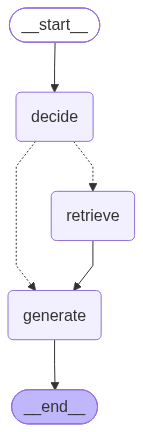

In [189]:
app

In [193]:
for name, value in list(globals().items()):
    try:
        if (
            isinstance(value, list)
            and len(value) > 0
            and hasattr(value[0], "page_content")
            and hasattr(value[0], "metadata")
        ):
            print(f"{name} -> {len(value)} documents")

        elif hasattr(value, "docstore") and hasattr(value, "index"):
            print(f"{name} -> Possible FAISS vector store")

    except Exception:
        pass

documents -> 430 documents
vector_store -> Possible FAISS vector store
results -> 58 documents
unique_results -> 19 documents
candidates -> 60 documents
ranked_results -> 30 documents
matching_results -> 30 documents


In [191]:
# response = llm.invoke(
#     "Reply with exactly: LLM is working."
# )

# print("LLM response:", repr(response.content))

In [194]:
all_documents = documents

In [195]:
question = "Find phones with 4000mah battery."

result = ask_question(question)

print("\nQuestion:", question)
print("\nAnswer:")
print(result.get("answer", result))


Question: Find phones with 4000mah battery.

Answer:
**Phones with a 4000 mAh battery**

| Brand & Model | RAM | ROM | Battery | Price |
|---|---:|---:|---:|---:|
| 5 Poco F1 | 6 GB | 128 GB | 4000 mAh | ₹18999.0 |
| 8.87 Realme C2 | 3 GB | 32 GB | 4000 mAh | ₹7499.0 |
| Poco F1 | 8 GB | 256 GB | 4000 mAh | ₹21999.0 |
| Realme C2 | 2 GB | 16 GB | 4000 mAh | ₹6499.0 |
| Realme C2 | 2 GB | 16 GB | 4000 mAh | ₹6499.0 |
| Realme C2 | 2 GB | 32 GB | 4000 mAh | ₹6999.0 |
| Samsung Galaxy A20 | 3 GB | 32 GB | 4000 mAh | ₹11490.0 |
| Samsung Galaxy A20s | 3 GB | 32 GB | 4000 mAh | ₹11599.0 |
| Samsung Galaxy A20s | 3 GB | 32 GB | 4000 mAh | ₹11599.0 |
| Samsung Galaxy A20s | 3 GB | 32 GB | 4000 mAh | ₹11599.0 |
| Samsung Galaxy A20s | 4 GB | 64 GB | 4000 mAh | ₹13695.0 |
| Samsung Galaxy A20s | 4 GB | 64 GB | 4000 mAh | ₹13695.0 |
| Samsung Galaxy A50s | 4 GB | 128 GB | 4000 mAh | ₹14999.0 |
| Samsung Galaxy A50s | 4 GB | 128 GB | 4000 mAh | ₹14999.0 |
| Samsung Galaxy A51 | 6 GB | 128 GB | 4